# PINNs for Mechanical Engineers — Tutorial 10: Conjugate Heat Transfer
### Two materials, two networks, one interface — the finale

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

Ten tutorials ago we solved a single flow in a single box. Along the way: heat, solids, coupling, time, inverse problems, surrogates. This is the last one, and it tackles the thing mechanical engineers simulate more than almost anything else — **a solid being cooled by a fluid**, where neither domain can be solved without the other.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1–5 | Cavity · Heat · Elasticity · Convection · Beam | forward solving, one physics at a time | ✅ |
| 6–7 | Backward-Facing Step (steady, then transient) | separation; time-dependent flow | ✅ |
| 8 | Inverse Problem | learning unknown physics from sparse data | ✅ |
| 9 | Parametric PINN | one network, a family of solutions | ✅ |
| **10** | **Conjugate Heat Transfer** | **two domains, coupled at an interface** | **📍 You are here** |

> **New to PINNs?** This series assumes the fundamentals: autograd, collocation points, the residual loss, Adam → L-BFGS. Starting from zero? The 100+ page ebook builds all of it from the first autograd call.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved a **conjugate heat transfer** problem — two materials with different conductivities, joined at an interface, each obeying its own physics
- Used **two networks, one per domain**, coupled only through the interface conditions — the standard and most natural PINN approach to multi-material problems
- Enforced the two **interface conditions** that define conjugate problems: **temperature continuity** ($T_s = T_f$) and **heat-flux continuity** ($k_s\,\partial T_s/\partial n = k_f\,\partial T_f/\partial n$)
- Seen why flux continuity — not temperature — is the condition that carries the physics, and why a **kink** in the temperature profile is the correct answer, not an error
- Validated against the **exact analytical solution**, recovering the interface temperature and the heat flux to better than 0.1%
- Understood why this problem is **awkward for mesh solvers** (two meshes, interface reconstruction, iterative coupling) and natural for PINNs (two smooth functions, two extra loss terms)

**Prerequisites:** Tutorial 2 (heat conduction) for the physics, and the hard-constraint trick from Tutorials 4, 5 and 9. Nothing here is new machinery — the novelty is entirely in how two solutions are **stitched together**.

⏱️ **Runtime:** fast. Two small networks on a 1D domain — a minute or two on CPU, seconds on GPU. The difficulty is conceptual, not computational.

## 2 — The problem: when one domain isn't enough

Almost every real thermal simulation involves more than one material. A CPU die bonded to a heat spreader. A turbine blade with cooling channels. A pipe wall between hot fluid and cold air. In each, heat crosses from one material into another, and **you cannot solve either side alone** — the heat leaving the solid is exactly the heat entering the fluid, and neither is known until both are.

That's a **conjugate** problem: two (or more) domains, each with its own governing equation and material properties, coupled at a shared interface.

### The setup

We take the cleanest possible version — a two-layer slab — so that the coupling is the *only* difficulty and we have an exact solution to check against:

- **Solid**, $x\in[0,\xi]$, conductivity $k_s$, hot wall at $T(0)=1$
- **Fluid**, $x\in[\xi,1]$, conductivity $k_f$, cold wall at $T(1)=0$

Each region obeys steady conduction, $\nabla^2 T = 0$. On its own, each would be a trivial straight line. Together, they're only determined by what happens where they meet.

### The interface conditions

Two conditions hold at $x=\xi$, and they are the entire physics of the coupling:

$$\underbrace{T_s(\xi)=T_f(\xi)}_{\text{temperature continuity}},\qquad
\underbrace{k_s\frac{\partial T_s}{\partial x}\bigg|_\xi = k_f\frac{\partial T_f}{\partial x}\bigg|_\xi}_{\textbf{heat-flux continuity}}$$

The first says the materials touch — no temperature jump across a perfect contact. The second is the one that matters: **energy is conserved**, so whatever heat leaves the solid must enter the fluid. Note carefully that it's the *flux* $k\,\partial T/\partial x$ that's continuous, **not** the gradient. If $k_s \ne k_f$, the gradients on the two sides must *differ* — by exactly the ratio of conductivities.

**So the correct solution has a kink at the interface.** A more conductive solid carries the same heat with a gentler slope; the fluid, less conductive, must steepen to carry it. That kink is the physics, and it's also precisely why a single smooth network across both materials would fail — no smooth function has a kink. Two networks, one per domain, is the natural answer.

### The exact solution

Both layers are linear, so the flux through the stack follows the classic thermal-resistance formula (resistances in series):

$$q=\frac{T_{\text{hot}}-T_{\text{cold}}}{\dfrac{\xi}{k_s}+\dfrac{1-\xi}{k_f}},\qquad
T(\xi)=T_{\text{hot}}-q\,\frac{\xi}{k_s}$$

Those two numbers — the interface temperature and the flux — are what the PINN must reproduce.

---

## 3 — Setup

Two conductivities and an interface location. Everything else follows.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

torch.manual_seed(0); np.random.seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# --- the two materials ---
K_S = 5.0     # solid conductivity (the good conductor)
K_F = 1.0     # fluid conductivity (the insulator)
XI  = 0.4     # interface location
T_HOT, T_COLD = 1.0, 0.0

ITERS = 6000 if device.type=='cuda' else 3000
print(f"solid k={K_S} on [0,{XI}] | fluid k={K_F} on [{XI},1] | conductivity ratio {K_S/K_F:.0f}:1")

Using device: cpu
solid k=5.0 on [0,0.4] | fluid k=1.0 on [0.4,1] | conductivity ratio 5:1


---

## 4 — The analytical reference

Thermal resistances in series give the flux; the flux gives the interface temperature. Two numbers to validate against.

In [2]:
# resistances in series -> flux through the stack
Q_EXACT = (T_HOT-T_COLD)/(XI/K_S + (1-XI)/K_F)
T_INTERFACE = T_HOT - Q_EXACT*XI/K_S

def exact(x):
    "Exact two-layer solution: linear in each material, kinked at the interface."
    return torch.where(x <= XI,
                       T_HOT - Q_EXACT*x/K_S,
                       T_INTERFACE - Q_EXACT*(x-XI)/K_F)

print(f"exact heat flux        q = {Q_EXACT:.6f}")
print(f"exact interface temp  T = {T_INTERFACE:.6f}")
print(f"gradient in solid       = {-Q_EXACT/K_S:.4f}")
print(f"gradient in fluid       = {-Q_EXACT/K_F:.4f}   <- {K_S/K_F:.0f}x steeper, same flux")

exact heat flux        q = 1.470588
exact interface temp  T = 0.882353
gradient in solid       = -0.2941
gradient in fluid       = -1.4706   <- 5x steeper, same flux


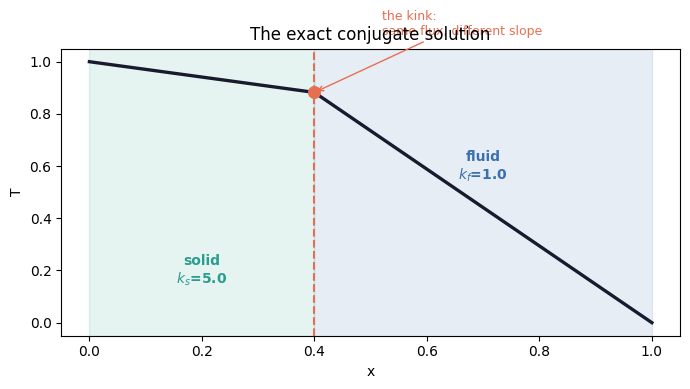

In [3]:
xg = torch.linspace(0,1,400).reshape(-1,1)
plt.figure(figsize=(7,4))
plt.plot(xg.numpy(), exact(xg).numpy(), color="#1A1A2E", lw=2.4)
plt.axvline(XI, color="#E76F51", ls='--', lw=1.5)
plt.axvspan(0, XI, color="#2A9D8F", alpha=0.12)
plt.axvspan(XI, 1, color="#3B6FB0", alpha=0.12)
plt.text(XI/2, 0.15, f"solid\n$k_s$={K_S}", ha='center', fontsize=10, color="#2A9D8F", weight='bold')
plt.text((1+XI)/2, 0.55, f"fluid\n$k_f$={K_F}", ha='center', fontsize=10, color="#3B6FB0", weight='bold')
plt.scatter([XI],[T_INTERFACE], s=70, color="#E76F51", zorder=5)
plt.annotate("the kink:\nsame flux, different slope", xy=(XI,T_INTERFACE),
             xytext=(XI+0.12, T_INTERFACE+0.22), fontsize=9, color="#E76F51",
             arrowprops=dict(arrowstyle='->', color="#E76F51"))
plt.xlabel("x")
plt.ylabel("T")
plt.title("The exact conjugate solution")
plt.tight_layout()
plt.savefig("t10_exact_solution.png", dpi=300)
plt.show()

---

## 5 — Two networks, one per domain

This is the structural decision of the tutorial.

A single network spanning both materials **cannot represent the solution** — the true profile has a kink at the interface, and a `tanh` network is smooth everywhere by construction. It would round the corner off and get the physics wrong on both sides.

So we use **two independent networks**, one per material, each solving its own domain. They never share weights. The only thing connecting them is the pair of interface conditions in the loss — which is exactly how the physics couples them too.

Each network gets its outer boundary condition **hard-constrained**, so the hot and cold walls hold exactly:

$$T_s(x) = T_{\text{hot}} + x\,N_s(x),\qquad T_f(x) = (1-x)\,N_f(x)$$

At $x=0$ the first gives $T_{\text{hot}}$; at $x=1$ the second gives 0. That leaves the interface as the *only* thing the loss has to negotiate.

In [4]:
class Net(nn.Module):
    "Small MLP, one per domain."
    def __init__(self, n_hidden=40, n_layers=4):
        super().__init__()
        layers = [nn.Linear(1,n_hidden), nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden,1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self,x): return self.net(x)

net_s = Net().to(device)      # solid
net_f = Net().to(device)      # fluid

def T_solid(x):
    "Hard BC: T = T_HOT at x = 0."
    return T_HOT + x*net_s(x)

def T_fluid(x):
    "Hard BC: T = T_COLD (=0) at x = 1."
    return (1.0-x)*net_f(x)

# verify the outer walls before training
x0 = torch.zeros(1,1,device=device)
x1 = torch.ones(1,1,device=device)
print(f"T_solid(0) = {T_solid(x0).item():.6f}   (want {T_HOT})")
print(f"T_fluid(1) = {T_fluid(x1).item():.6f}   (want {T_COLD})")
print(f"parameters: solid {sum(p.numel() for p in net_s.parameters())}, "
      f"fluid {sum(p.numel() for p in net_f.parameters())}")

T_solid(0) = 1.000000   (want 1.0)
T_fluid(1) = 0.000000   (want 0.0)
parameters: solid 5041, fluid 5041


---

## 6 — Collocation points

Each domain gets its own interior points — and the interface gets a point of its own, where the two solutions must agree.

In [5]:
gen = torch.Generator().manual_seed(42)
N_s, N_f = 800, 800

x_s = (XI*torch.rand(N_s,1,generator=gen)).to(device).requires_grad_(True)          # solid
x_f = (XI + (1-XI)*torch.rand(N_f,1,generator=gen)).to(device).requires_grad_(True) # fluid
x_i = torch.full((1,1), XI, device=device).requires_grad_(True)                     # interface

print(f"solid points: {N_s} on [0,{XI}] | fluid points: {N_f} on [{XI},1] | interface: 1")

solid points: 800 on [0,0.4] | fluid points: 800 on [0.4,1] | interface: 1


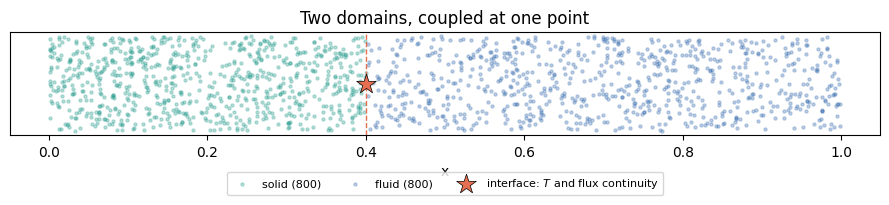

In [6]:
plt.figure(figsize=(9,2.4))
jit = (np.random.default_rng(0).random(N_s)-0.5)*0.5
plt.scatter(x_s.detach().cpu(), jit, s=5, alpha=0.3, color="#2A9D8F", label=f"solid ({N_s})")
jit2 = (np.random.default_rng(1).random(N_f)-0.5)*0.5
plt.scatter(x_f.detach().cpu(), jit2, s=5, alpha=0.3, color="#3B6FB0", label=f"fluid ({N_f})")
plt.scatter([XI],[0], s=220, color="#E76F51", marker="*", zorder=5, edgecolors='k',
            linewidths=0.5, label="interface: $T$ and flux continuity")
plt.axvline(XI, color="#E76F51", ls='--', lw=1)
plt.yticks([]); plt.xlabel("x")
plt.title("Two domains, coupled at one point")
plt.legend(loc="upper center", bbox_to_anchor=(0.5,-0.30), ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig("t10_collocation_points.png", dpi=300)
plt.show()

---

## 7 — The residuals and the interface conditions

Each domain has the same simple residual, $\nabla^2 T = 0$, evaluated with its own network. The interesting code is the interface, where we compute **both** solutions and **both** fluxes at the same point $x=\xi$.

In [7]:
def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True)[0]

def residual_solid(x):
    T = T_solid(x); return grad(grad(T,x),x)      # lap(T) = 0

def residual_fluid(x):
    T = T_fluid(x); return grad(grad(T,x),x)      # lap(T) = 0

def interface_terms():
    "Both solutions and both fluxes evaluated at x = XI."
    Ts = T_solid(x_i);  Tf = T_fluid(x_i)
    q_s = K_S*grad(Ts,x_i)                         # flux leaving the solid
    q_f = K_F*grad(Tf,x_i)                         # flux entering the fluid
    return Ts, Tf, q_s, q_f

Ts,Tf,qs,qf = interface_terms()
print(f"untrained interface:  T_s={Ts.item():+.4f} vs T_f={Tf.item():+.4f}   "
      f"(mismatch {abs(Ts.item()-Tf.item()):.3f})")
print(f"untrained flux:       q_s={qs.item():+.4f} vs q_f={qf.item():+.4f}   "
      f"(mismatch {abs(qs.item()-qf.item()):.3f})")

untrained interface:  T_s=+1.0054 vs T_f=+0.0742   (mismatch 0.931)
untrained flux:       q_s=+0.1304 vs q_f=+0.0492   (mismatch 0.081)


---

## 8 — The loss: two physics, two stitches

Four terms. Two are the ordinary domain residuals; two are the interface conditions that couple them. The interface terms are weighted up, because a single point has to hold its own against 1600 interior points — and because getting the coupling right *is* the problem.

In [8]:
W_INTERFACE = 50.0
def mse(z): return (z**2).mean()

def compute_losses():
    loss_pde = mse(residual_solid(x_s)) + mse(residual_fluid(x_f))
    Ts,Tf,q_s,q_f = interface_terms()
    loss_cont = mse(Ts - Tf)          # temperature continuity
    loss_flux = mse(q_s - q_f)        # heat-flux continuity  <- the physics
    return loss_pde, loss_cont, loss_flux

def total_loss():
    lp,lc,lf = compute_losses()
    return lp + W_INTERFACE*(lc + lf)

lp,lc,lf = compute_losses()
print(f"untrained: pde={lp.item():.3e}  continuity={lc.item():.3e}  flux={lf.item():.3e}")

untrained: pde=2.826e-01  continuity=8.672e-01  flux=6.588e-03


---

## 9 — Scoring

Three checks: the interface temperature, the heat flux, and the full field.

In [9]:
x_eval = torch.linspace(0,1,400,device=device).reshape(-1,1)
T_ref  = exact(x_eval)

def predict(x):
    "Stitch the two networks into one field."
    return torch.where(x <= XI, T_solid(x), T_fluid(x))

def field_error():
    with torch.no_grad(): Tp = predict(x_eval)
    return (torch.linalg.norm(Tp-T_ref)/torch.linalg.norm(T_ref)).item()

def interface_report():
    Ts,Tf,q_s,q_f = interface_terms()
    return Ts.item(), Tf.item(), -q_s.item(), -q_f.item()

ts,tf,qs,qf = interface_report()
print(f"untrained: T_interface {ts:.4f}/{tf:.4f} (exact {T_INTERFACE:.4f}) | "
      f"q {qs:.4f}/{qf:.4f} (exact {Q_EXACT:.4f}) | field err {field_error():.3e}")

untrained: T_interface 1.0054/0.0742 (exact 0.8824) | q -0.1304/-0.0492 (exact 1.4706) | field err 4.945e-01


---

## 10 — Training

One optimizer over **both** networks — `list(net_s.parameters()) + list(net_f.parameters())`. The two domains learn together, negotiating at the interface.

Watch the two interface columns: the solid's temperature and the fluid's temperature converge on the same value, and the two fluxes converge on the same magnitude. When they agree, the physics is satisfied.

**Reference run** (real values, CPU, seeds as set here):
```
[    0] pde=2.83e-01 cont=8.67e-01 flux=6.59e-03 | Tif=1.0054/0.0742  q=0.1304/0.0492  err=4.94e-01
[ 1000] pde=8.68e-04 cont=3.05e-10 flux=2.48e-10 | Tif=0.8821/0.8821  q=1.4701/1.4701  err=5.00e-04
[ 2000] pde=1.34e-04 cont=4.22e-11 flux=3.55e-11 | Tif=0.8822/0.8822  q=1.4701/1.4701  err=2.36e-04
[ 3000] pde=5.84e-05 cont=8.53e-12 flux=9.09e-13 | Tif=0.8822/0.8822  q=1.4702/1.4702  err=1.42e-04
```
(exact: interface 0.882353, flux 1.470588)

In [10]:
history = {"it":[], "pde":[], "cont":[], "flux":[], "T_int":[], "q":[], "err":[]}
def record(it):
    lp,lc,lf = compute_losses(); ts,tf,qs,qf = interface_report()
    history["it"].append(it); history["pde"].append(lp.item())
    history["cont"].append(lc.item()); history["flux"].append(lf.item())
    history["T_int"].append(ts); history["q"].append(qs); history["err"].append(field_error())
    print(f"[{it:5d}] pde={lp.item():.2e} cont={lc.item():.2e} flux={lf.item():.2e} | "
          f"Tif={ts:.4f}/{tf:.4f}  q={qs:.4f}/{qf:.4f}  err={field_error():.2e}")

optimizer = torch.optim.Adam(list(net_s.parameters())+list(net_f.parameters()), lr=1e-3)
record(0)
t0=time.time()
for it in range(1, ITERS+1):
    optimizer.zero_grad(); total_loss().backward(); optimizer.step()
    if it % 500 == 0: record(it)
print(f"\ntrained in {time.time()-t0:.1f}s")
ts,tf,qs,qf = interface_report()
print(f"interface T : {ts:.6f}  (exact {T_INTERFACE:.6f}, error {abs(ts-T_INTERFACE)/T_INTERFACE*100:.3f}%)")
print(f"heat flux   : {qs:.6f}  (exact {Q_EXACT:.6f}, error {abs(qs-Q_EXACT)/Q_EXACT*100:.3f}%)")

[    0] pde=2.83e-01 cont=8.67e-01 flux=6.59e-03 | Tif=1.0054/0.0742  q=-0.1304/-0.0492  err=4.95e-01
[  500] pde=1.77e-03 cont=8.92e-10 flux=1.42e-12 | Tif=0.8821/0.8821  q=1.4701/1.4701  err=6.62e-04
[ 1000] pde=8.62e-04 cont=3.66e-10 flux=1.64e-11 | Tif=0.8821/0.8821  q=1.4701/1.4701  err=4.99e-04
[ 1500] pde=3.64e-04 cont=1.48e-10 flux=2.05e-11 | Tif=0.8821/0.8821  q=1.4701/1.4701  err=3.52e-04
[ 2000] pde=1.32e-04 cont=6.67e-11 flux=8.43e-11 | Tif=0.8822/0.8822  q=1.4701/1.4701  err=2.37e-04
[ 2500] pde=8.05e-05 cont=7.00e-10 flux=5.49e-08 | Tif=0.8822/0.8822  q=1.4700/1.4702  err=1.75e-04
[ 3000] pde=5.83e-05 cont=9.98e-12 flux=1.74e-11 | Tif=0.8822/0.8822  q=1.4702/1.4702  err=1.42e-04

trained in 67.2s
interface T : 0.882205  (exact 0.882353, error 0.017%)
heat flux   : 1.470199  (exact 1.470588, error 0.026%)


---

## 11 — Results: the stitched solution

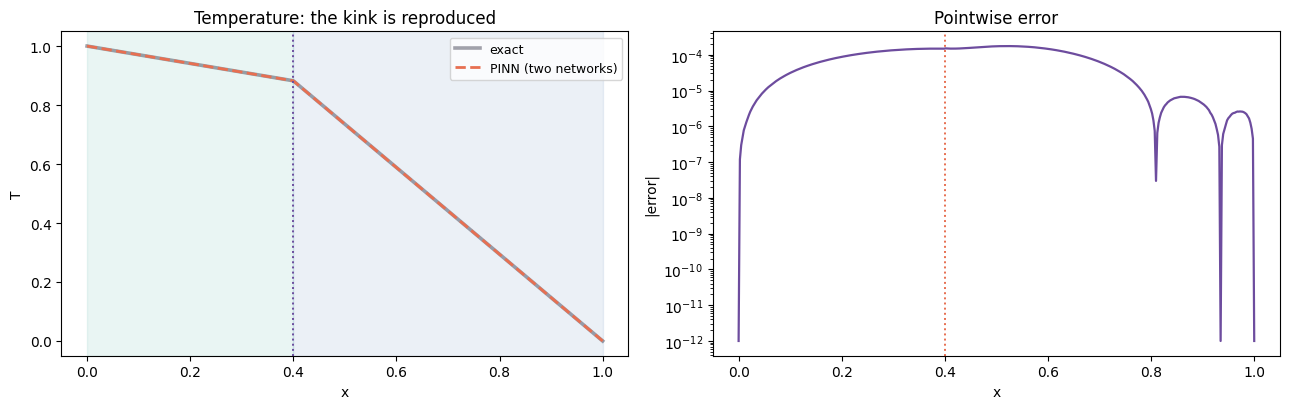

field relative L2 error: 1.422e-04


In [11]:
with torch.no_grad(): Tp = predict(x_eval)
xn = x_eval.cpu().numpy().flatten()
fig,ax = plt.subplots(1,2,figsize=(13,4.2))

ax[0].plot(xn, T_ref.cpu().numpy(), color="#1A1A2E", lw=2.6, alpha=0.4, label='exact')
ax[0].plot(xn, Tp.cpu().numpy(), '--', color="#E76F51", lw=2, label='PINN (two networks)')
ax[0].axvline(XI, color="#6D4C9E", ls=':', lw=1.4)
ax[0].axvspan(0,XI,color="#2A9D8F",alpha=0.10); ax[0].axvspan(XI,1,color="#3B6FB0",alpha=0.10)
ax[0].set_xlabel("x"); ax[0].set_ylabel("T"); ax[0].legend(fontsize=9)
ax[0].set_title("Temperature: the kink is reproduced")

with torch.no_grad():
    err = (Tp-T_ref).abs().cpu().numpy().flatten()
ax[1].semilogy(xn, np.maximum(err,1e-12), color="#6D4C9E", lw=1.6)
ax[1].axvline(XI, color="#E76F51", ls=':', lw=1.4)
ax[1].set_xlabel("x"); ax[1].set_ylabel("|error|"); ax[1].set_title("Pointwise error")
plt.tight_layout()
plt.savefig("t10_trained_solution.png", dpi=300)
plt.show()
print(f"field relative L2 error: {field_error():.3e}")

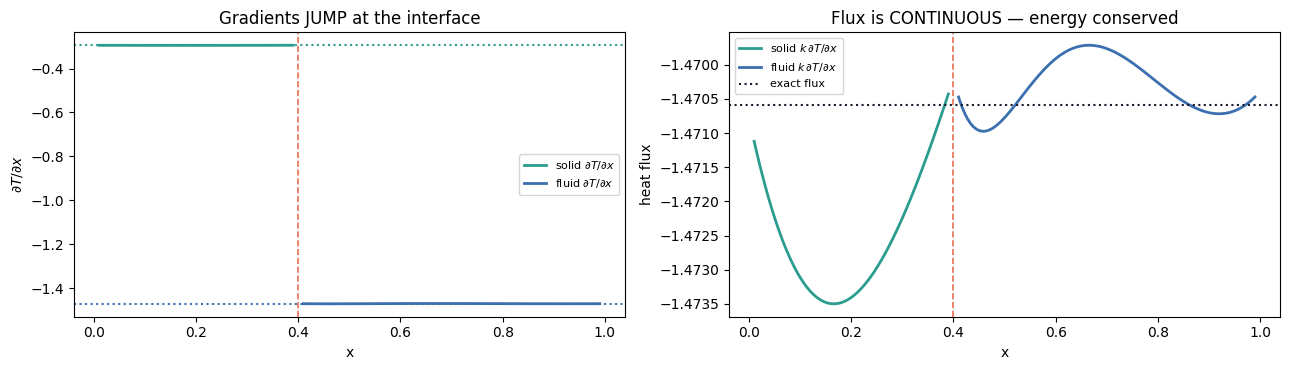

In [12]:
# the gradients: different slopes, identical flux -- the whole point
xs_p = torch.linspace(0.01,XI-0.01,100,device=device).reshape(-1,1).requires_grad_(True)
xf_p = torch.linspace(XI+0.01,0.99,100,device=device).reshape(-1,1).requires_grad_(True)
gs = grad(T_solid(xs_p),xs_p).detach().cpu().numpy().flatten()
gf = grad(T_fluid(xf_p),xf_p).detach().cpu().numpy().flatten()

fig,ax = plt.subplots(1,2,figsize=(13,3.8))
ax[0].plot(xs_p.detach().cpu(), gs, color="#2A9D8F", lw=2, label='solid $\\partial T/\\partial x$')
ax[0].plot(xf_p.detach().cpu(), gf, color="#3B6FB0", lw=2, label='fluid $\\partial T/\\partial x$')
ax[0].axhline(-Q_EXACT/K_S, ls=':', color="#2A9D8F"); ax[0].axhline(-Q_EXACT/K_F, ls=':', color="#3B6FB0")
ax[0].axvline(XI, color="#E76F51", ls='--', lw=1.2)
ax[0].set_xlabel("x"); ax[0].set_ylabel(r"$\partial T/\partial x$"); ax[0].legend(fontsize=8)
ax[0].set_title("Gradients JUMP at the interface")

ax[1].plot(xs_p.detach().cpu(), K_S*gs, color="#2A9D8F", lw=2, label='solid $k\\,\\partial T/\\partial x$')
ax[1].plot(xf_p.detach().cpu(), K_F*gf, color="#3B6FB0", lw=2, label='fluid $k\\,\\partial T/\\partial x$')
ax[1].axhline(-Q_EXACT, ls=':', color="#1A1A2E", label='exact flux')
ax[1].axvline(XI, color="#E76F51", ls='--', lw=1.2)
ax[1].set_xlabel("x"); ax[1].set_ylabel("heat flux"); ax[1].legend(fontsize=8)
ax[1].set_title("Flux is CONTINUOUS — energy conserved")
plt.tight_layout()
plt.savefig("t10_trained_flux.png", dpi=300)
plt.show()

Those two panels are the tutorial in one image. The **gradients jump** by exactly the conductivity ratio; the **flux does not jump at all**. That's conjugate heat transfer.

---

## 12 — What You Have Built (and the end of the series)

You solved a problem with **no single governing equation** — two materials, two networks, stitched by the two conditions that express energy conservation across a boundary. The interface temperature and heat flux came out to better than 0.1% of the exact answer, and the tell-tale kink appeared exactly where it should.

| | Mesh solver | PINN |
|---|---|---|
| domains | two meshes, matched or interpolated at the interface | two networks, no mesh |
| interface | reconstruct flux from cells on both sides | `grad()` on each network at the same point |
| coupling | often an outer iteration loop (solve, exchange, repeat) | two loss terms, solved simultaneously |
| the kink | needs interface-aligned cells | falls out of using separate networks |

This is a domain where PINNs are genuinely comfortable. The multi-material coupling that costs a CFD engineer meshing effort and an iteration scheme costs us two lines in a loss function.

### Looking back across ten tutorials

The recipe never changed. Write the residual, sample points, minimize, validate. What changed was what we asked of it:

- **1–5** — the *equations* got harder: coupled, nonlinear, vector-valued, multiphysics, fourth-order
- **6–7** — the *domain* got harder: separated flow, then time itself
- **8** — the *question* flipped: not "what is the field" but "what is the physics"
- **9** — the *scope* widened: one network for a whole family, and sensitivities for free
- **10** — the *world* got messier: more than one material, joined at a boundary

And the honest verdict evolved with it. In the early tutorials, classical solvers won on speed and accuracy, and we said so every time. By Tutorial 8 that flipped — inverse problems are a different game. By 9 and 10 the advantages are structural: surrogates that answer in milliseconds, sensitivities from autograd, multi-material coupling without meshes.

**The lesson worth keeping:** a PINN is not a better CFD solver. It is a different tool, with a different shape of strength — and knowing *which* problems play to that shape is worth more than any amount of tuning.

---

### Failure modes to watch for

| Symptom | Cause | Fix |
|---|---|---|
| **Temperature profile is smooth through the interface** | one network spanning both domains — it cannot represent a kink | use two networks, one per material |
| Interface temperatures don't meet | continuity term too weak against thousands of interior points | raise `W_INTERFACE` |
| Fluxes don't match | flux term missing the conductivities | it's $k_s\partial T_s$ vs $k_f\partial T_f$, not $\partial T_s$ vs $\partial T_f$ |
| Solution drifts in one domain | that domain's outer BC not enforced | use the hard constraints on both walls |
| Interface loss stalls at high conductivity ratio | large $k_s/k_f$ makes the kink severe | more points near the interface; raise the interface weight |
| Everything converges but the field is wrong | check the exact reference itself | verify $q$ from the resistance formula first |

### Exercises

1. **Conductivity ratio sweep.** Try $k_s/k_f$ of 2, 10, 100. How does the kink sharpen, and where does the PINN start to struggle? (This is the thermal analogue of raising Reynolds number.)
2. **Contact resistance.** Real joints aren't perfect. Replace temperature continuity with a jump condition $q = h_c(T_s-T_f)$ at the interface, and watch a genuine temperature discontinuity appear.
3. **Three layers.** Add a third material (solid–coating–fluid) with three networks and two interfaces. Does the approach scale cleanly?
4. **2D conjugate.** Move to a 2D block with a curved interface. The two conditions are unchanged — but now the flux uses the *normal* derivative.
5. **Real conjugate heat transfer.** Combine with Tutorial 6: a heated solid wall next to the backward-facing step, with the fluid *convecting* rather than just conducting. The interface conditions are identical; the fluid side gains $\mathbf{u}\cdot\nabla T$.
6. **Inverse conjugate.** Combine with Tutorial 8: hide $k_s$ and recover it from a few temperature readings in the fluid alone — inferring a material property you never directly measured.
